# Nettoyage de la Data
## Initialistaion

In [1]:
import pandas as pd

# On garde seulement les colonnes qui nous sont utiles pour alléger et optimiser
colonnes_voulues = ["raceId","driverId","lap","time"]
df_times = pd.read_csv("../data/02_silver/lap_times.csv", usecols=colonnes_voulues)

df_times.shape #test

(640262, 4)

## Renommage des colonnes
On renomme les colonnes pour qu'on se conforme au dictionnaire.

In [2]:
df_times = df_times.rename(columns={
    "raceId": "id_grand_prix",
    "driverId": "id_pilote",
    "lap": "id_lap",
    "time": "lap_time"
})

df_times.head()

,id_grand_prix,id_pilote,id_lap,lap_time
0,841,20,1,1:38.109
1,841,20,2,1:33.006
2,841,20,3,1:32.713
3,841,20,4,1:32.803
4,841,20,5,1:32.342


## Fusion de cette table avec races.csv
Pour pouvoir filtrer par période (on étudie seulement la période 1997-2026), on va avoir besoin de la table races.csv qui répertories pour chaque GP, leur nom (ca sera plus facile pour les identifier) mais surtout leur année.

,id_grand_prix,id_pilote,id_lap,lap_time,year,id_circuit
113821,224,30,28,1:36.526,1996,1
113853,224,56,28,1:36.549,1996,1
113820,224,30,27,1:36.842,1996,1
113819,224,30,26,1:34.081,1996,1
113818,224,30,25,1:34.408,1996,1


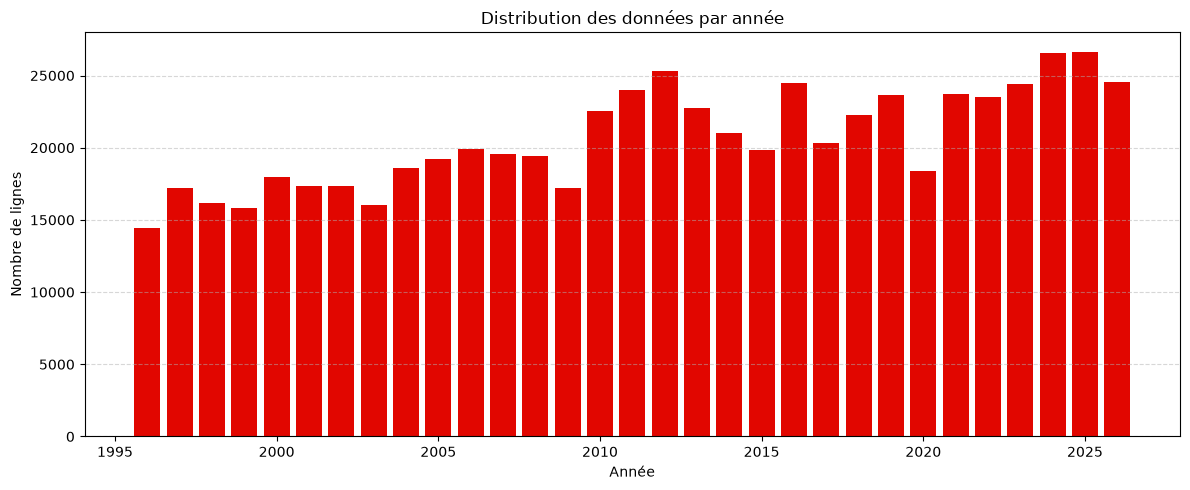

In [3]:
import matplotlib.pyplot as plt

# Import de la 2e table
colonnes_voulues = ["raceId","year","circuitId"]
df_races = pd.read_csv("../data/02_silver/races.csv", usecols=colonnes_voulues)

#Pareil que pour la 1e, on renomme les colonnes
df_races = df_races.rename(columns={
    "raceId": "id_grand_prix",
    "circuitId": "id_circuit"
})

df_fusion = pd.merge(
    df_times,
    df_races,
    left_on="id_grand_prix",
    right_on="id_grand_prix",
    how="left"
)

display(df_fusion.sort_values(["year"]).head())

# Vérification de la distribution des années sur chaque ligne de lap_times.csv
distrib_annees = df_fusion["year"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
plt.bar(distrib_annees.index, distrib_annees.values, color="#E10600", width=0.8)

plt.title("Distribution des données par année")
plt.xlabel("Année")
plt.ylabel("Nombre de lignes")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# On peut voir qu'on a qu'une seule année à retirer pour que ce fichier soit conforme à notre scope défini

## Filtrage par année
On peut donc maintenant filtrer les lignes de lap_times par année

In [4]:
df_fusion = df_fusion[df_fusion["year"] >= 1997]

display(df_fusion.sort_values(["year"]).head())

df_fusion.shape

,id_grand_prix,id_pilote,id_lap,lap_time,year,id_circuit
128227,207,64,3,1:36.702,1997,1
128228,207,64,4,1:35.111,1997,1
128229,207,64,5,1:36.376,1997,1
128230,207,64,6,1:35.809,1997,1
128231,207,64,7,1:36.285,1997,1


(625831, 6)

## Fusion avec circuits.csv
On veut seulement les lap_times des circuits concernés, c'est à dire ceux présents dans le fichier gold circuits.csv, on le fusionne donc avec les lap_times.

In [5]:
df_circuits = pd.read_csv("../data/03_gold/circuits.csv")

df_fusion = pd.merge(
    df_fusion,
    df_circuits,
    left_on="id_circuit",
    right_on="id_circuit",
    how="right"
)

display(df_fusion.shape)
display(df_fusion.head())

(143726, 10)

,id_grand_prix,id_pilote,id_lap,lap_time,year,id_circuit,nom_circuit,nom_officiel,id_pays,url_img_circuit
0,846,20,1,1:24.839,2011,6,monaco,Circuit de Monaco,MC,https://img.redbull.com/image/upload/e_trim:10...
1,846,20,2,1:20.269,2011,6,monaco,Circuit de Monaco,MC,https://img.redbull.com/image/upload/e_trim:10...
2,846,20,3,1:19.811,2011,6,monaco,Circuit de Monaco,MC,https://img.redbull.com/image/upload/e_trim:10...
3,846,20,4,1:19.485,2011,6,monaco,Circuit de Monaco,MC,https://img.redbull.com/image/upload/e_trim:10...
4,846,20,5,1:19.537,2011,6,monaco,Circuit de Monaco,MC,https://img.redbull.com/image/upload/e_trim:10...


# Suppression des colonnes non-pertinentes
Notre future table `resultats_laps`, on a seulement besoin de `id_grand_prix`, `id_pilote`, `id_lap`, `lap_time`

In [6]:
df_fusion = df_fusion[["id_grand_prix", "id_pilote", "id_lap", "lap_time"]]

display(df_fusion.shape)
display(df_fusion.head())

(143726, 4)

,id_grand_prix,id_pilote,id_lap,lap_time
0,846,20,1,1:24.839
1,846,20,2,1:20.269
2,846,20,3,1:19.811
3,846,20,4,1:19.485
4,846,20,5,1:19.537


## Fusion avec 

## Fusion avec results et constructors pour récupérer les écuries et le status

## Export modifications vers un fichier .csv

In [7]:
df_fusion.to_csv("../data/03_gold/resultats_laps.csv", index=False, encoding="utf-8")